# German Credit: exploratory analysis

Statlog German Credit (UCI), decoded by `ml/prepare_data.py`. Target `default` = 1 for a bad payer.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "backend").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "backend"))
from app.domain.features import FEATURES, BY_NAME

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
df = pd.read_csv(ROOT / "ml/data/processed/german_credit.csv")
train = pd.read_csv(ROOT / "ml/data/processed/train.csv")
test = pd.read_csv(ROOT / "ml/data/processed/test.csv")
print(df.shape, train.shape, test.shape)
df.head()

(1000, 22) (800, 22) (200, 22)


,applicant_id,credit_amount,duration_months,purpose,installment_rate,other_debtors,checking_status,savings,credit_history,existing_credits,...,employment,job,housing,residence_since,telephone,age,sex,dependents,foreign_worker,default
0,GC-0001,1169,6,radio_tv,4,none,negative,unknown,critical,2,...,ge_7y,skilled,own,4,True,67,male,1,True,0
1,GC-0002,5951,48,radio_tv,2,none,low,lt_100,existing_paid,1,...,1_to_4y,skilled,own,2,False,22,female,1,True,1
2,GC-0003,2096,12,education,2,none,no_account,lt_100,critical,1,...,4_to_7y,unskilled_resident,own,3,False,49,male,2,True,0
3,GC-0004,7882,42,furniture,2,guarantor,negative,lt_100,existing_paid,1,...,4_to_7y,skilled,free,4,False,45,male,2,True,0
4,GC-0005,4870,24,car_new,3,none,negative,lt_100,past_delays,2,...,1_to_4y,skilled,free,4,False,53,male,2,True,1


## Structure and quality

In [2]:
summary = pd.DataFrame({
    "kind": [BY_NAME[c].kind for c in df.columns if c in BY_NAME],
    "distinct": [df[c].nunique() for c in df.columns if c in BY_NAME],
    "missing": [int(df[c].isna().sum()) for c in df.columns if c in BY_NAME],
    "recourse": [BY_NAME[c].recourse for c in df.columns if c in BY_NAME],
    "protected": [BY_NAME[c].protected for c in df.columns if c in BY_NAME],
}, index=[c for c in df.columns if c in BY_NAME])
print("duplicated rows:", int(df.drop(columns='applicant_id').duplicated().sum()))
summary

duplicated rows: 0


,kind,distinct,missing,recourse,protected
credit_amount,numeric,921,0,request,False
duration_months,numeric,33,0,request,False
purpose,categorical,10,0,fixed,False
installment_rate,numeric,4,0,fixed,False
other_debtors,categorical,3,0,request,False
checking_status,categorical,4,0,situation,False
savings,categorical,5,0,situation,False
credit_history,categorical,5,0,fixed,False
existing_credits,numeric,4,0,situation,False
other_installment_plans,categorical,3,0,situation,False


## Target

In [3]:
print(df["default"].value_counts().rename({0: "repaid", 1: "defaulted"}))
print("default rate  all %.3f | train %.3f | test %.3f" % (df["default"].mean(), train["default"].mean(), test["default"].mean()))

default
repaid       700
defaulted    300
Name: count, dtype: int64
default rate  all 0.300 | train 0.300 | test 0.300


## Numeric attributes

In [4]:
nums = [f.name for f in FEATURES if f.kind == "numeric"]
df[nums].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
credit_amount,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
duration_months,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
installment_rate,1000.0,3.0,1.1,1.0,2.0,3.0,4.0,4.0
existing_credits,1000.0,1.4,0.6,1.0,1.0,1.0,2.0,4.0
residence_since,1000.0,2.8,1.1,1.0,2.0,3.0,4.0,4.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0
dependents,1000.0,1.2,0.4,1.0,1.0,1.0,1.0,2.0


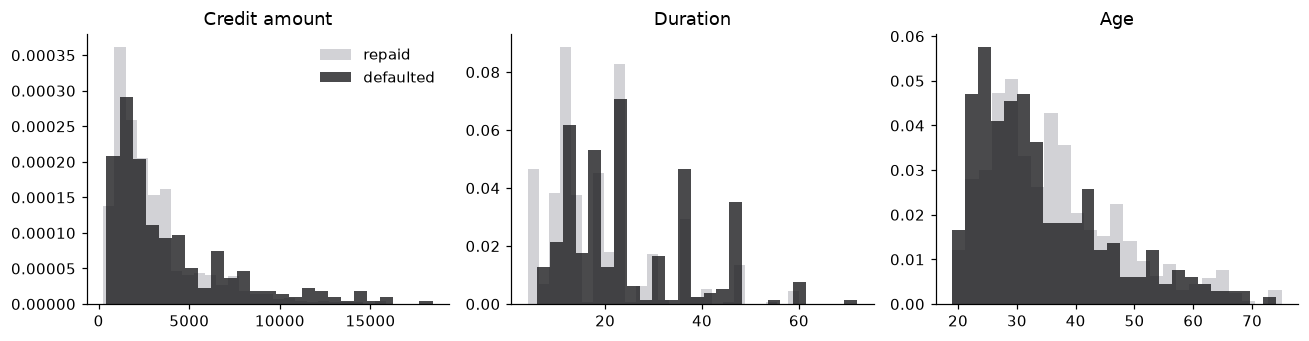

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, ["credit_amount", "duration_months", "age"]):
    for value, color, label in [(0, "#c7c7cc", "repaid"), (1, "#1d1d1f", "defaulted")]:
        ax.hist(df.loc[df["default"] == value, col], bins=25, alpha=0.8, color=color, label=label, density=True)
    ax.set_title(BY_NAME[col].label)
axes[0].legend(frameon=False)
plt.tight_layout()

Default rate by quartile of amount and by duration band: risk grows with both, which supports the monotone constraints used in the model.

In [6]:
out = pd.DataFrame({
    "by amount quartile": df.groupby(pd.qcut(df["credit_amount"], 4), observed=True)["default"].mean().round(3).to_list(),
    "by duration band": df.groupby(pd.cut(df["duration_months"], [0, 12, 24, 36, 72]), observed=True)["default"].mean().round(3).to_list(),
}, index=["lowest", "second", "third", "highest"])
out

,by amount quartile,by duration band
lowest,0.308,0.212
second,0.248,0.297
third,0.224,0.399
highest,0.420,0.517


## Categorical attributes: default rate by value

In [7]:
cats = [f.name for f in FEATURES if f.kind != "numeric"]
rows = []
for c in cats:
    g = df.groupby(c)["default"].agg(["mean", "size"])
    for value, r in g.iterrows():
        rows.append({"attribute": BY_NAME[c].label, "value": BY_NAME[c].label_of(value), "default rate": round(r["mean"], 3), "files": int(r["size"])})
by_value = pd.DataFrame(rows)
by_value.sort_values("default rate", ascending=False).head(12)

,attribute,value,default rate,files
25,Credit history,No credit taken,0.625,40
22,Credit history,All credits at this bank repaid,0.571,49
15,Checking account,Overdrawn (below 0 DM),0.493,274
4,Purpose,Education,0.440,50
10,Co-applicant or guarantor,Co-applicant,0.439,41
31,Most valuable property,Unknown or none,0.435,154
6,Purpose,Other,0.417,12
27,Other instalment plans,At another bank,0.410,139
37,Time in current employment,Less than 1 year,0.407,172
43,Housing,Free of charge,0.407,108


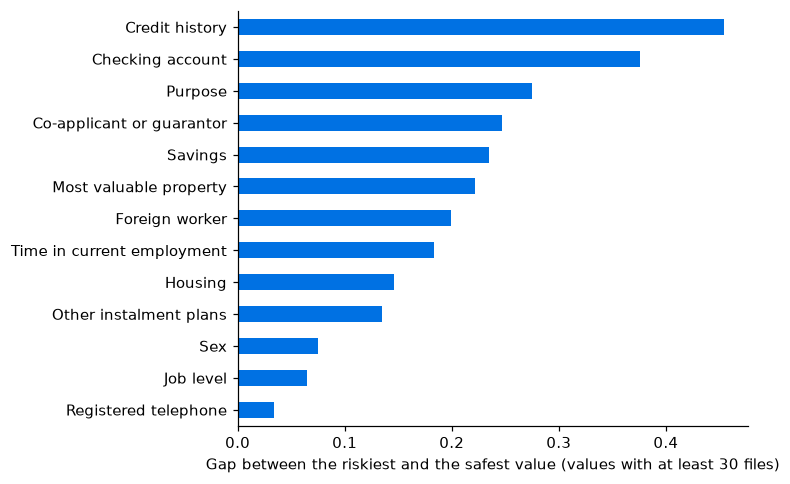

In [8]:
spread = by_value[by_value["files"] >= 30].groupby("attribute")["default rate"].agg(lambda s: s.max() - s.min()).sort_values()
ax = spread.plot.barh(figsize=(7, 4.5), color="#0071e3")
ax.set_xlabel("Gap between the riskiest and the safest value (values with at least 30 files)")
ax.set_ylabel("")
plt.tight_layout()

## Protected attributes

Sex is derived from the personal status code. Group sizes are unbalanced, and foreign workers are 96% of the files, which limits what can be concluded for that attribute.

In [9]:
df["age_group"] = np.where(df["age"] <= 25, "25 or younger", "older than 25")
pd.concat([
    df.groupby("sex")["default"].agg(["mean", "size"]),
    df.groupby("age_group")["default"].agg(["mean", "size"]),
    df.groupby("foreign_worker")["default"].agg(["mean", "size"]).rename(index={True: "foreign worker", False: "not foreign worker"}),
]).round(3).rename(columns={"mean": "default rate", "size": "files"})

,default rate,files
female,0.352,310
male,0.277,690
25 or younger,0.421,190
older than 25,0.272,810
not foreign worker,0.108,37
foreign worker,0.307,963


## Attributes an applicant can act on

These are the only attributes the counterfactual search may change.

In [10]:
pd.DataFrame([{"attribute": f.label, "scope": f.recourse, "direction": {-1: "decrease only", 0: "improve along ladder", 1: "increase only"}[f.direction],
               "ladder": " > ".join(f.ladder)} for f in FEATURES if f.recourse != "fixed"])

,attribute,scope,direction,ladder
0,Credit amount,request,decrease only,
1,Duration,request,decrease only,
2,Co-applicant or guarantor,request,improve along ladder,none > guarantor
3,Checking account,situation,improve along ladder,negative > low > high
4,Savings,situation,improve along ladder,lt_100 > 100_to_500 > 500_to_1000 > ge_1000
5,Existing credits at this bank,situation,decrease only,
6,Other instalment plans,situation,improve along ladder,bank > none


## Association between numeric attributes

In [11]:
df[nums + ["default"]].corr(method="spearman").round(2)

,credit_amount,duration_months,installment_rate,existing_credits,residence_since,age,dependents,default
credit_amount,1.00,0.62,-0.31,0.02,0.02,0.03,0.04,0.09
duration_months,0.62,1.00,0.12,0.03,0.04,-0.04,-0.04,0.21
installment_rate,-0.31,0.12,1.00,0.02,0.05,0.07,-0.07,0.07
existing_credits,0.02,0.03,0.02,1.00,0.07,0.14,0.10,-0.05
residence_since,0.02,0.04,0.05,0.07,1.00,0.23,0.04,0.00
age,0.03,-0.04,0.07,0.14,0.23,1.00,0.19,-0.11
dependents,0.04,-0.04,-0.07,0.10,0.04,0.19,1.00,-0.00
default,0.09,0.21,0.07,-0.05,0.00,-0.11,-0.00,1.00
